<a href="https://colab.research.google.com/github/adhilpareed82/cleaned-student-dataset/blob/main/Text_Data_Cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas openpyxl nltk

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk

from nltk.corpus import stopwords
from google.colab import files

In [ ]:
uploaded = files.upload()

Saving Uncleaned_Student_Performance_Dataset_200.csv to Uncleaned_Student_Performance_Dataset_200 (1).csv


In [ ]:
import pandas as pd

file_name = '/content/Uncleaned_Student_Performance_Dataset_200.csv'

df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")

display(df.head(10))

Dataset Loaded Successfully!


,Student_ID,Student_Name,Age,Department,Attendance,Internal_Marks,Assignment_Score,Study_Hours,Final_Marks,Gender,City
0,2001,Student_1,19.0,ME,85.2,30.0,NaN,3.1,44.0,M,Bengaluru
1,2002,Student_2,17.0,ME,77.9,92.0,92.0,8.2,NaN,F,Kozhikode
2,2003,Student_3,22.0,CE,48.5,42.0,33.0,4.9,97.0,M,Kozhikode
3,2004,Student_4,22.0,ME,93.2,97.0,88.0,5.7,47.0,M,Thrissur
4,2005,Student_5,22.0,ME,93.2,53.0,37.0,4.6,72.0,F,Bengaluru
5,2006,Student_6,21.0,EEE,63.2,83.0,41.0,0.9,64.0,F,Chennai
6,2007,Student_7,22.0,CE,63.7,NaN,60.0,2.1,87.0,M,Kochi
7,2008,Student_8,17.0,CSE,99.4,41.0,63.0,4.7,62.0,M,Kozhikode
8,2009,Student_9,19.0,ECE,79.4,46.0,78.0,2.5,43.0,F,Bengaluru
9,2010,Student_10,21.0,ME,74.2,92.0,86.0,1.0,63.0,M,Bengaluru


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (200, 11)

Column Names:
['Student_ID', 'Student_Name', 'Age', 'Department', 'Attendance', 'Internal_Marks', 'Assignment_Score', 'Study_Hours', 'Final_Marks', 'Gender', 'City']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Student_ID        200 non-null    int64  
 1   Student_Name      200 non-null    object 
 2   Age               194 non-null    float64
 3   Department        200 non-null    object 
 4   Attendance        190 non-null    float64
 5   Internal_Marks    192 non-null    float64
 6   Assignment_Score  192 non-null    float64
 7   Study_Hours       190 non-null    float64
 8   Final_Marks       192 non-null    float64
 9   Gender            194 non-null    object 
 10  City              194 non-null    object 
dtypes: float64(6), int64(1), object(4)
memory usage: 17.3+ KB

Missin

In [ ]:
print(df.isnull().sum())

Student_ID           0
Student_Name         0
Age                  6
Department           0
Attendance          10
Internal_Marks       8
Assignment_Score     8
Study_Hours         10
Final_Marks          8
Gender               6
City                 6
dtype: int64


In [ ]:
TEXT_COLUMN = 'Student_Name'

df = df.dropna(subset=[TEXT_COLUMN])

print("Missing Student Names Removed")

Missing Student Names Removed


In [ ]:
TEXT_COLUMNS = ['Student_Name', 'Department', 'Gender', 'City']

df = df.dropna(subset=TEXT_COLUMNS)

print("Missing Text Values Removed")

Missing Text Values Removed


In [ ]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Columns:
['Student_ID', 'Student_Name', 'Age', 'Department', 'Attendance', 'Internal_Marks', 'Assignment_Score', 'Study_Hours', 'Final_Marks', 'Gender', 'City']

Missing Values:
Student_ID           0
Student_Name         0
Age                  5
Department           0
Attendance           9
Internal_Marks       8
Assignment_Score     8
Study_Hours         10
Final_Marks          8
Gender               0
City                 0
dtype: int64


In [ ]:


numerical_columns = [
    'Age',
    'Attendance',
    'Internal_Marks',
    'Assignment_Score',
    'Study_Hours',
    'Final_Marks'
]

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing Values Filled Successfully!")

Missing Values Filled Successfully!


In [ ]:
df.isnull().sum()


,0
Student_ID,0
Student_Name,0
Age,0
Department,0
Attendance,0
Internal_Marks,0
Assignment_Score,0
Study_Hours,0
Final_Marks,0
Gender,0


In [ ]:
df.head(10)

,Student_ID,Student_Name,Age,Department,Attendance,Internal_Marks,Assignment_Score,Study_Hours,Final_Marks,Gender,City
0,2001,Student_1,19.0,ME,85.2,30.0,62.5,3.1,44.0,M,Bengaluru
1,2002,Student_2,17.0,ME,77.9,92.0,92.0,8.2,67.0,F,Kozhikode
2,2003,Student_3,22.0,CE,48.5,42.0,33.0,4.9,97.0,M,Kozhikode
3,2004,Student_4,22.0,ME,93.2,97.0,88.0,5.7,47.0,M,Thrissur
4,2005,Student_5,22.0,ME,93.2,53.0,37.0,4.6,72.0,F,Bengaluru
5,2006,Student_6,21.0,EEE,63.2,83.0,41.0,0.9,64.0,F,Chennai
6,2007,Student_7,22.0,CE,63.7,60.0,60.0,2.1,87.0,M,Kochi
7,2008,Student_8,17.0,CSE,99.4,41.0,63.0,4.7,62.0,M,Kozhikode
8,2009,Student_9,19.0,ECE,79.4,46.0,78.0,2.5,43.0,F,Bengaluru
9,2010,Student_10,21.0,ME,74.2,92.0,86.0,1.0,63.0,M,Bengaluru


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

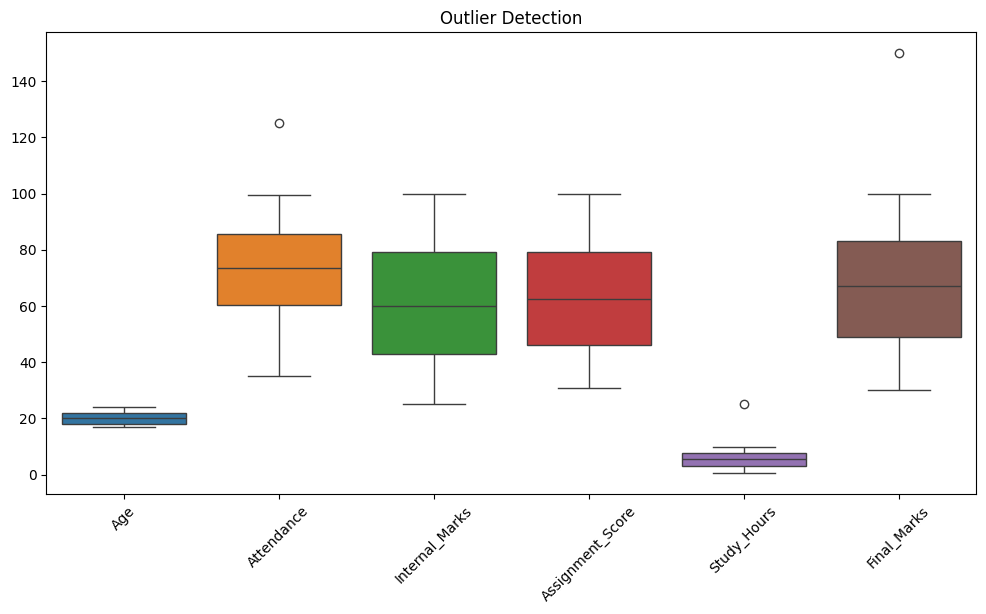

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = [
    'Age',
    'Attendance',
    'Internal_Marks',
    'Assignment_Score',
    'Study_Hours',
    'Final_Marks'
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numerical_columns])

plt.xticks(rotation=45)
plt.title("Outlier Detection")
plt.show()

In [ ]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

Age Outliers: 0
Attendance Outliers: 1
Internal_Marks Outliers: 0
Assignment_Score Outliers: 0
Study_Hours Outliers: 1
Final_Marks Outliers: 1


In [ ]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    if len(outliers) > 0:
        print("\nOutliers in:", col)
        display(outliers[['Student_ID', 'Student_Name', col]])


Outliers in: Attendance


,Student_ID,Student_Name,Attendance
12,2013,Student_13,125.0



Outliers in: Study_Hours


,Student_ID,Student_Name,Study_Hours
72,2073,Student_73,25.0



Outliers in: Final_Marks


,Student_ID,Student_Name,Final_Marks
155,2156,Student_156,150.0


In [ ]:
# Check invalid Attendance

print(df[df['Attendance'] > 100])

# Check invalid Final Marks

print(df[df['Final_Marks'] > 100])

# Check unusual Study Hours

print(df[df['Study_Hours'] > 24])

    Student_ID Student_Name   Age Department  Attendance  Internal_Marks  \
12        2013   Student_13  19.0        ECE       125.0            73.0   

    Assignment_Score  Study_Hours  Final_Marks Gender       City  
12              67.0          8.0         88.0      M  Bengaluru  
     Student_ID Student_Name   Age Department  Attendance  Internal_Marks  \
155        2156  Student_156  22.0        CSE        73.4            58.0   

     Assignment_Score  Study_Hours  Final_Marks Gender       City  
155              33.0          8.2        150.0      M  Bengaluru  
    Student_ID Student_Name   Age Department  Attendance  Internal_Marks  \
72        2073   Student_73  23.0        EEE        73.4            75.0   

    Assignment_Score  Study_Hours  Final_Marks Gender        City  
72              38.0         25.0         91.0      M  Trivandrum  


In [ ]:
# Replace invalid Attendance

attendance_median = df.loc[
    df['Attendance'].between(0, 100),
    'Attendance'
].median()

df.loc[df['Attendance'] > 100, 'Attendance'] = attendance_median


# Replace invalid Final Marks

marks_median = df.loc[
    df['Final_Marks'].between(0, 100),
    'Final_Marks'
].median()

df.loc[df['Final_Marks'] > 100, 'Final_Marks'] = marks_median


# Replace invalid Study Hours

study_median = df.loc[
    df['Study_Hours'].between(0, 24),
    'Study_Hours'
].median()

df.loc[df['Study_Hours'] > 24, 'Study_Hours'] = study_median

print("Invalid Values Corrected!")

Invalid Values Corrected!


In [ ]:
print("Attendance above 100:")
print((df['Attendance'] > 100).sum())

print("Final Marks above 100:")
print((df['Final_Marks'] > 100).sum())

print("Study Hours above 24:")
print((df['Study_Hours'] > 24).sum())

Attendance above 100:
0
Final Marks above 100:
0
Study Hours above 24:
0


In [ ]:
df.describe()

,Student_ID,Age,Attendance,Internal_Marks,Assignment_Score,Study_Hours,Final_Marks
count,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000
mean,2097.611702,20.425532,72.643617,61.925532,63.345745,5.411170,66.085106
std,57.407943,2.296192,15.460397,21.438004,19.141540,2.693969,19.763392
min,2001.000000,17.000000,35.000000,25.000000,31.000000,0.500000,30.000000
25%,2048.750000,18.000000,60.200000,43.000000,46.000000,3.200000,49.000000
50%,2095.500000,20.000000,73.400000,60.000000,62.500000,5.400000,67.000000
75%,2146.250000,22.000000,85.300000,79.250000,79.250000,7.700000,82.250000
max,2200.000000,24.000000,99.500000,100.000000,100.000000,10.000000,100.000000


In [ ]:
# Check Age
print("Invalid Age:")
print(df[~df['Age'].between(17, 100)])

# Check Attendance
print("Invalid Attendance:")
print(df[~df['Attendance'].between(0, 100)])

# Check Internal Marks
print("Invalid Internal Marks:")
print(df[~df['Internal_Marks'].between(0, 100)])

# Check Assignment Score
print("Invalid Assignment Score:")
print(df[~df['Assignment_Score'].between(0, 100)])

# Check Study Hours
print("Invalid Study Hours:")
print(df[~df['Study_Hours'].between(0, 24)])

# Check Final Marks
print("Invalid Final Marks:")
print(df[~df['Final_Marks'].between(0, 100)])

Invalid Age:
Empty DataFrame
Columns: [Student_ID, Student_Name, Age, Department, Attendance, Internal_Marks, Assignment_Score, Study_Hours, Final_Marks, Gender, City]
Index: []
Invalid Attendance:
Empty DataFrame
Columns: [Student_ID, Student_Name, Age, Department, Attendance, Internal_Marks, Assignment_Score, Study_Hours, Final_Marks, Gender, City]
Index: []
Invalid Internal Marks:
Empty DataFrame
Columns: [Student_ID, Student_Name, Age, Department, Attendance, Internal_Marks, Assignment_Score, Study_Hours, Final_Marks, Gender, City]
Index: []
Invalid Assignment Score:
Empty DataFrame
Columns: [Student_ID, Student_Name, Age, Department, Attendance, Internal_Marks, Assignment_Score, Study_Hours, Final_Marks, Gender, City]
Index: []
Invalid Study Hours:
Empty DataFrame
Columns: [Student_ID, Student_Name, Age, Department, Attendance, Internal_Marks, Assignment_Score, Study_Hours, Final_Marks, Gender, City]
Index: []
Invalid Final Marks:
Empty DataFrame
Columns: [Student_ID, Student_Name

In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (188, 11)

Missing Values:
Student_ID          0
Student_Name        0
Age                 0
Department          0
Attendance          0
Internal_Marks      0
Assignment_Score    0
Study_Hours         0
Final_Marks         0
Gender              0
City                0
dtype: int64

Duplicate Rows:
0

Data Types:
Student_ID            int64
Student_Name         object
Age                 float64
Department           object
Attendance          float64
Internal_Marks      float64
Assignment_Score    float64
Study_Hours         float64
Final_Marks         float64
Gender               object
City                 object
dtype: object


In [ ]:
df.to_csv('final_cleaned_student_dataset.csv', index=False)

from google.colab import files
files.download('final_cleaned_student_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Save cleaned dataset

df.to_csv('final_cleaned_student_dataset.csv', index=False)

# Download dataset

from google.colab import files

files.download('final_cleaned_student_dataset.csv')

print("Dataset Saved Successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dataset Saved Successfully!


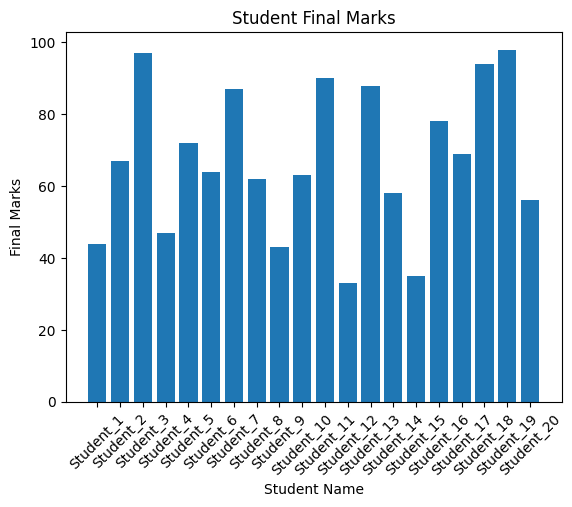

In [ ]:
import matplotlib.pyplot as plt

plt.bar(df['Student_Name'].head(20),
        df['Final_Marks'].head(20))

plt.title("Student Final Marks")
plt.xlabel("Student Name")
plt.ylabel("Final Marks")

plt.xticks(rotation=45)
plt.show()